# Fraud Risk Intelligence — Complete Analysis Notebook

**Internship assignment: Fraud Risk Intelligence Pipeline (sections A–K).**  
This notebook provides a readable interface to your **existing modular Python analysis** and its saved results.

> **Default is safe/read-only:** In the project you have already completed, choose **Run All**. It reads your reports and charts **without retraining, recalibrating, reselecting thresholds, or rescoring the held-out test set**. Your complete source is in `src/`, with the execution order documented in `08_README.md`. The option to reproduce from scratch only works in a separate, clean copy.

**Status:** Offline prototype, not approved for production. Business costs are hypothetical.

## Setup — project root and optional fresh-copy reproduction

Run this notebook from the existing `fraud-risk-intelligence-day01` folder using the `.venv` Python kernel. All paths are relative to that project root. `RUN_FROM_SCRATCH` is intentionally **False** in your existing project.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
assert (ROOT / "src" / "model_training.py").exists(), (
    "Open the notebook from the existing fraud-risk-intelligence-day01 project root."
)
RUN_FROM_SCRATCH = False
print("Project:", ROOT)
print("Notebook mode:", "FRESH-COPY REPRODUCTION" if RUN_FROM_SCRATCH else "READ SAVED RESULTS ONLY")

Project: c:\Users\ASUS\Desktop\Internship\fraud-risk-intelligence-day01
Notebook mode: READ SAVED RESULTS ONLY


In [2]:
if RUN_FROM_SCRATCH:
    import subprocess, sys
    protected = [ROOT / "models/03_fraud_model_pipeline.joblib",
                 ROOT / "models/04_calibrated_model.joblib",
                 ROOT / "reports/final_evaluation/10_final_test_metrics.json"]
    if any(p.exists() for p in protected):
        raise RuntimeError("Never rerun a finalized experiment over existing fitted models or final-test results. Make a clean copy first.")
    stages = ["data_audit", "eda_analysis", "feature_engineering", "model_training",
              "imbalance_calibration", "business_cost_decision", "explainable_ai",
              "robustness_stress_testing", "final_test_evaluation", "governance_reports"]
    for stage in stages:
        print("Reproducing:", stage)
        subprocess.run([sys.executable, str(ROOT / "src" / (stage + ".py"))], check=True)
else:
    print("Safe mode: reusing completed outputs; no model training or test scoring.")

Safe mode: reusing completed outputs; no model training or test scoring.


## A. Data forensics and quality engineering

Audit the schema, missingness, duplicates, category cardinality, numerical ranges, and impossible values. **Important:** `authentication_level = "None"` is a valid category, not a missing observation. The source CSV is not modified.

In [3]:
raw_path = ROOT / "data/raw/transaction_fraud_risk_advanced_dataset.csv"
df = pd.read_csv(raw_path, keep_default_na=False, na_values=[""])
print("Shape:", df.shape)
print("Fraud counts:\n", df["fraud"].value_counts().to_string())
print("Missing values (nonzero):\n", df.isna().sum()[lambda s: s.gt(0)].to_string())
print("Duplicate full rows:", df.duplicated().sum())
display(df.head())

Shape: (3000, 25)
Fraud counts:
 fraud
0    2636
1     364
Missing values (nonzero):
 transaction_amount                 53
distance_from_usual_location_km    75
merchant_risk_score                60
ip_risk_score                      45
login_to_transaction_minutes       60
Duplicate full rows: 0


,transaction_id,hour,day_of_week,transaction_amount,distance_from_usual_location_km,transactions_last_1h,transactions_last_24h,account_age_days,failed_logins_24h,prior_chargebacks,...,card_presence,channel,country,device_type,merchant_category,authentication_level,new_device,billing_address_mismatch,customer_tier,fraud
0,TXN5000001,20,0,35.01,47.93,6,12,783,0,0,...,Not present,E-commerce,Sri Lanka,iOS,Grocery,Standard,0,1,Basic,1
1,TXN5000002,4,1,29.66,78.02,2,6,564,0,0,...,Not present,POS,UK,macOS,Grocery,Strong,0,1,Basic,0
2,TXN5000003,0,4,46.05,21.39,5,10,1618,0,0,...,Present,E-commerce,Sri Lanka,Android,Grocery,Standard,0,0,Gold,0
3,TXN5000004,15,4,77.02,95.29,4,10,1433,1,0,...,Present,E-commerce,Sri Lanka,Other,Grocery,Strong,0,0,Basic,0
4,TXN5000005,8,3,187.65,6.08,1,10,50,0,0,...,Not present,POS,Sri Lanka,Android,Grocery,Standard,0,0,Basic,0


In [4]:
for label, filename in [
    ("Data quality audit", "reports/data_quality_audit.csv"),
    ("Domain validity checks", "reports/data_quality_issues.csv"),
    ("Missingness versus fraud", "reports/missingness_fraud_association.csv"),
]:
    path = ROOT / filename
    print("\n", label)
    if path.exists(): display(pd.read_csv(path).head(30))
    else: print("Not found:", filename)


 Data quality audit


,column,data_type,missing_count,missing_percent,unique_values
0,transaction_id,object,0,0.00,3000
1,hour,int64,0,0.00,24
2,day_of_week,int64,0,0.00,7
3,transaction_amount,float64,53,1.77,2779
4,distance_from_usual_location_km,float64,75,2.50,2402
5,transactions_last_1h,int64,0,0.00,11
6,transactions_last_24h,int64,0,0.00,25
7,account_age_days,int64,0,0.00,1464
8,failed_logins_24h,int64,0,0.00,4
9,prior_chargebacks,int64,0,0.00,4



 Domain validity checks


,check,count
0,invalid_hour_outside_0_to_23,0
1,invalid_day_outside_0_to_6,0
2,negative_transaction_amount,0
3,negative_distance_km,0
4,negative_account_age_days,0
5,invalid_merchant_risk_score,0
6,invalid_ip_risk_score,0
7,invalid_fraud_label,0



 Missingness versus fraud


,column,missing,transactions,fraud_rate_percent
0,transaction_amount,False,2947,12.18
1,transaction_amount,True,53,9.43
2,distance_from_usual_location_km,False,2925,12.31
3,distance_from_usual_location_km,True,75,5.33
4,merchant_risk_score,False,2940,12.31
5,merchant_risk_score,True,60,3.33
6,ip_risk_score,False,2955,12.15
7,ip_risk_score,True,45,11.11
8,login_to_transaction_minutes,False,2940,12.14
9,login_to_transaction_minutes,True,60,11.67


**Leakage assessment.** `fraud` is the target and `transaction_id` is an identifier, never a predictor. Upstream merchant/IP risk scores and behavioral counters are permissible only when available at prediction time. This dataset has no transaction timestamp or customer ID, so chronological and customer-group splits are not verifiable. A fixed stratified holdout and train-only learning are used instead.

In [5]:
for filename in ["reports/split_manifest.csv", "reports/modeling_split_manifest.csv"]:
    path=ROOT / filename
    print("\n", filename)
    if path.exists():
        manifest=pd.read_csv(path)
        print("Rows:",len(manifest), "Columns:", list(manifest.columns))
        for c in manifest.columns:
            if manifest[c].dtype == object and manifest[c].nunique() <= 8:
                print(c,manifest[c].value_counts().to_dict())
    else: print("Not found")


 reports/split_manifest.csv
Rows: 3000 Columns: ['transaction_id', 'split']
split {'development': 2400, 'test': 600}

 reports/modeling_split_manifest.csv
Rows: 3000 Columns: ['transaction_id', 'partition']
partition {'train': 1680, 'test': 600, 'calibration': 360, 'policy': 360}


## B. Advanced exploratory data analysis

The EDA script creates 20 charts, including three interaction charts. EDA was conducted on development records to avoid using the final held-out test labels for exploratory decision-making.

EDA charts: 20
01_fraud_class_distribution.png


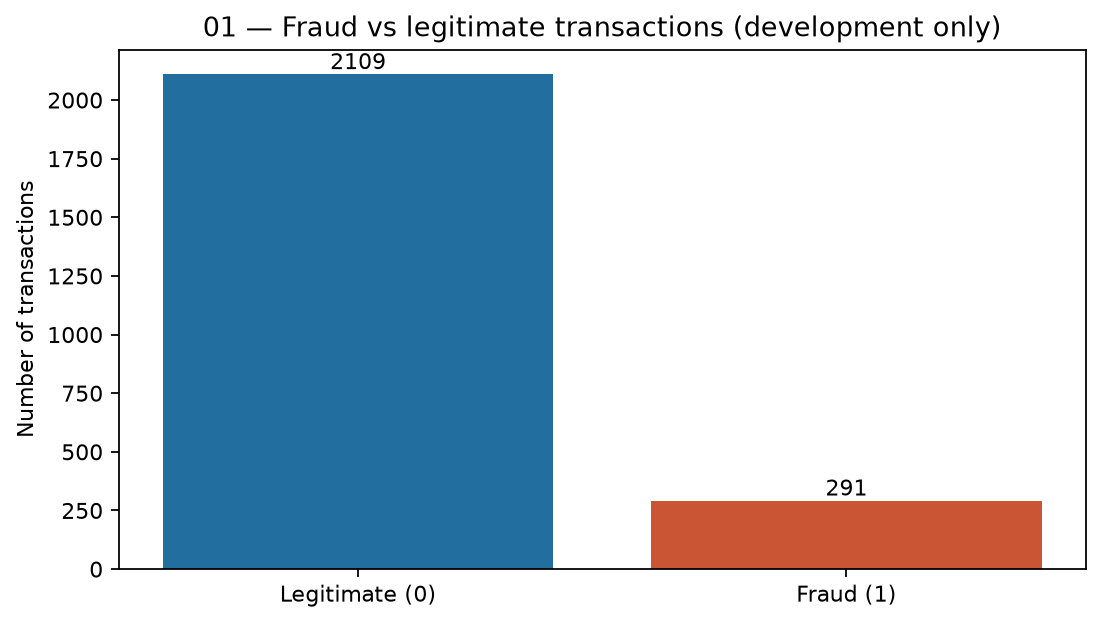

02_channel.png


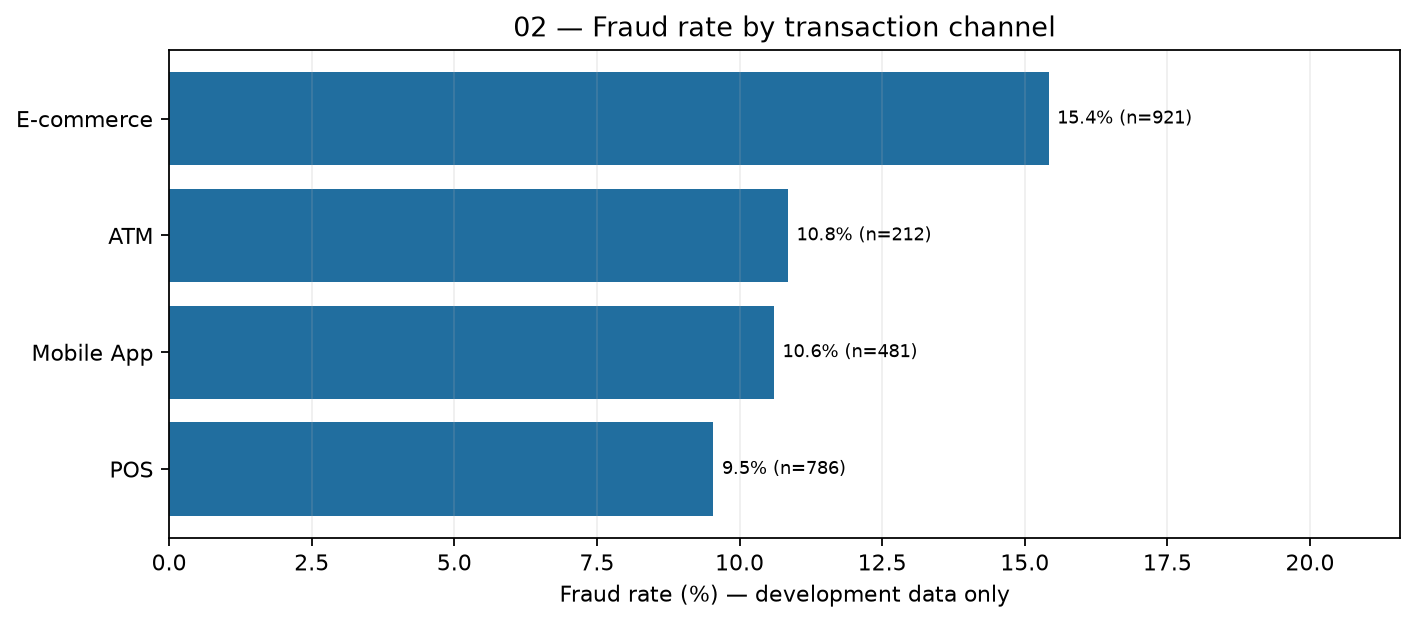

18_new_device_by_distance.png


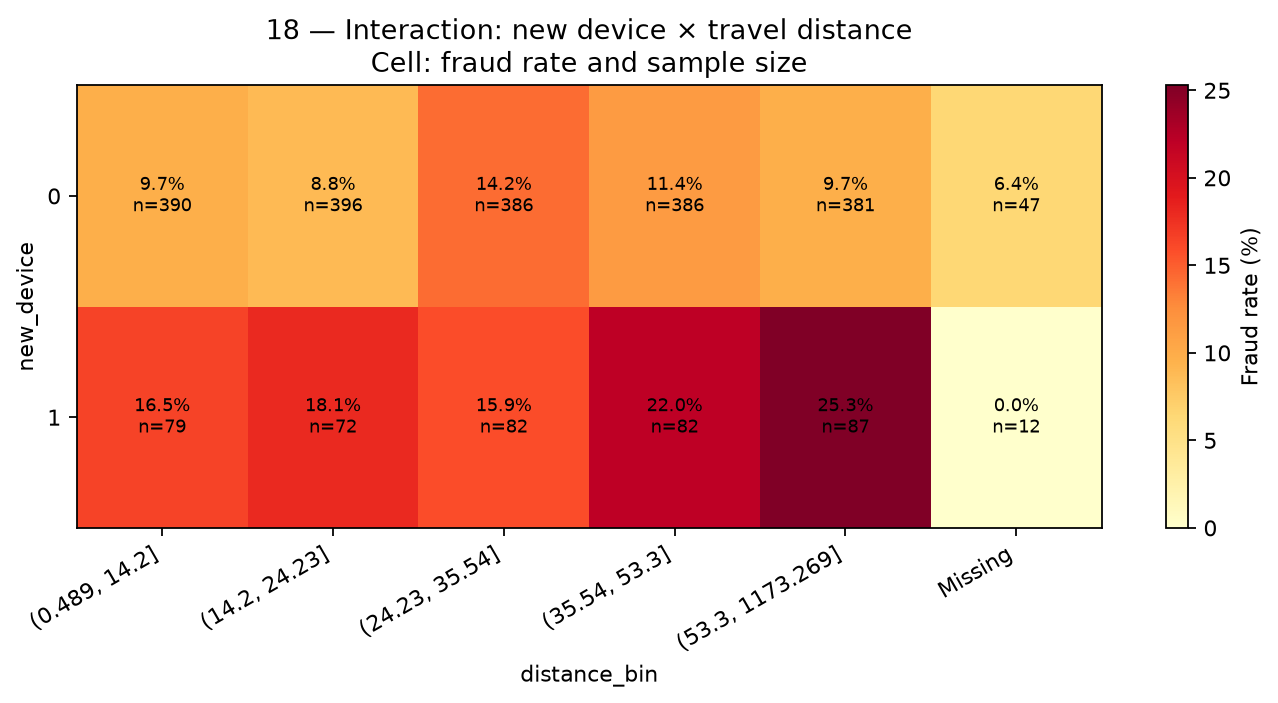

19_amount_by_merchant_risk.png


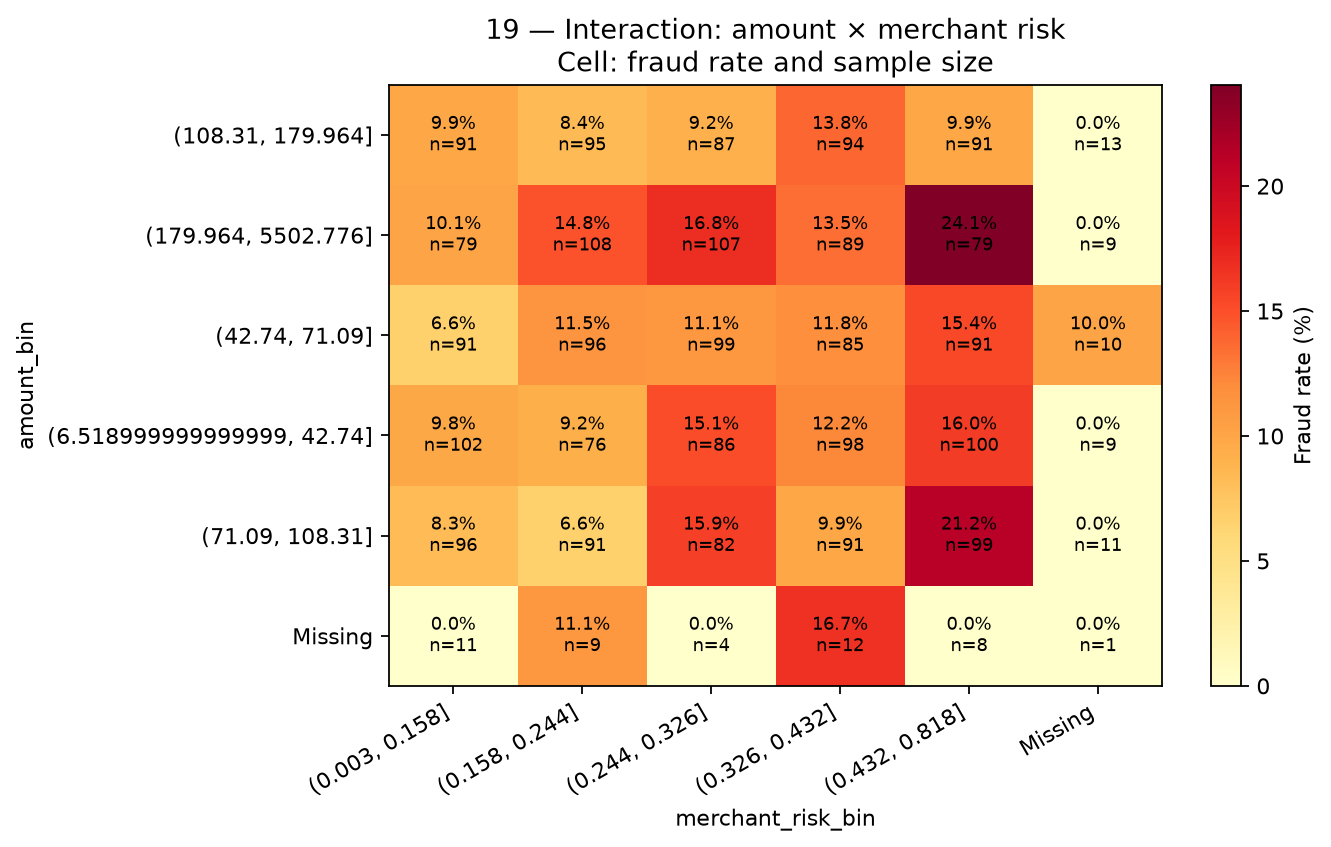

20_authentication_by_channel.png


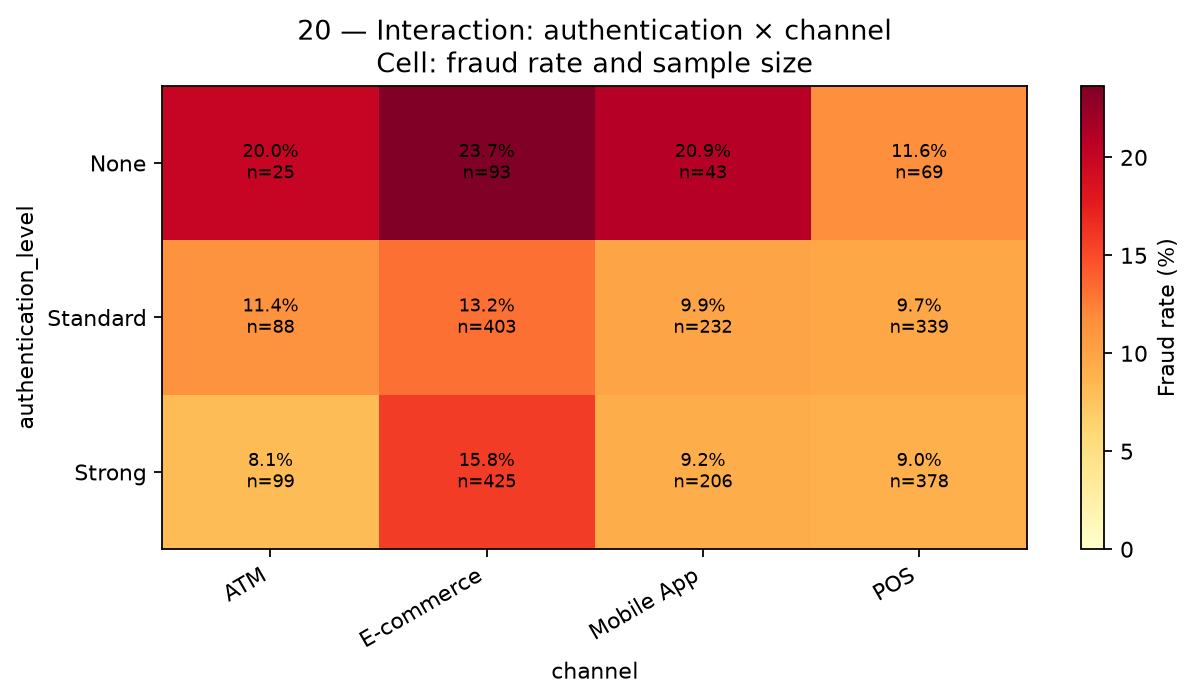

In [6]:
eda_dir = ROOT / "reports/eda"
plots=sorted(eda_dir.glob("*.png")) if eda_dir.exists() else []
print("EDA charts:", len(plots))
for name in ["01_fraud_class_distribution.png", "02_channel.png", "18_new_device_by_distance.png", "19_amount_by_merchant_risk.png", "20_authentication_by_channel.png"]:
    p=eda_dir/name
    if p.exists():
        print(name); display(Image(filename=str(p),width=720))
    else: print("Not found:",name)

## C. Feature engineering and ablation

The feature-engineering script creates 28 defensible derived columns, documenting calculations and their prediction-time assumptions in the feature catalog. Learned imputations and encodings are fitted in training/CV pipelines, **not** globally on the test set. Compare both original (23 predictors) and engineered (51 predictors) sets.

In [7]:
catalog=ROOT/'reports/feature_catalog.csv'
processed=ROOT/'data/processed/02_processed_dataset.csv'
if catalog.exists():
    features=pd.read_csv(catalog)
    print('Engineered feature catalog:',len(features),'entries')
    display(features)
if processed.exists():
    data=pd.read_csv(processed)
    print('Processed data shape:',data.shape)
    display(data.head(3))

Engineered feature catalog: 28 entries


,feature,feature_type,definition,source_columns
0,amount_log1p,Amount normalization,"log(1 + transaction amount), if amount >= 0",transaction_amount
1,amount_per_recent_24h_tx,Amount normalization,amount / (1 + transaction count in previous 24...,transaction_amount; transactions_last_24h
2,amount_per_recent_1h_tx,Amount normalization,amount / (1 + transaction count in previous hour),transaction_amount; transactions_last_1h
3,velocity_1h_share,Velocity ratio,last_1h / (1 + last_24h),transactions_last_1h; transactions_last_24h
4,velocity_24h_minus_1h,Velocity difference,last_24h - last_1h (negative values need inves...,transactions_last_24h; transactions_last_1h
5,distance_log1p,Distance transform,log(1 + km from usual location),distance_from_usual_location_km
6,night_transaction,Time-window indicator,"1 if hour is 22-23 or 00-05, else 0 (local-tim...",hour
7,hour_sin,Cyclic time,sin(2*pi*hour/24),hour
8,hour_cos,Cyclic time,cos(2*pi*hour/24),hour
9,day_of_week_sin,Cyclic time,sin(2*pi*day_of_week/7),day_of_week


Processed data shape: (3000, 54)


,transaction_id,hour,day_of_week,transaction_amount,distance_from_usual_location_km,transactions_last_1h,transactions_last_24h,account_age_days,failed_logins_24h,prior_chargebacks,...,amount_x_merchant_risk,failed_logins_x_ip_risk,new_device_x_address_mismatch,no_auth_x_new_device,auth_channel_pair,missing_transaction_amount,missing_distance,missing_merchant_risk,missing_ip_risk,missing_login_minutes
0,TXN5000001,20,0,35.01,47.93,6,12,783,0,0,...,21.74121,0.0,0,0,Standard__E-commerce,0,0,0,0,0
1,TXN5000002,4,1,29.66,78.02,2,6,564,0,0,...,16.40198,0.0,0,0,Strong__POS,0,0,0,0,0
2,TXN5000003,0,4,46.05,21.39,5,10,1618,0,0,...,18.69630,0.0,0,0,Standard__E-commerce,0,0,0,0,0


## D. Baseline, nonlinear models, and tuning

Three model families—Logistic Regression, Random Forest, and Histogram Gradient Boosting—are compared under 3-fold cross-validation, each with raw and engineered features. Hyperparameter search is performed on training records only. Use **PR-AUC** as the principal ranking metric, and review ROC-AUC, F1 and other outcomes in context.

In [8]:
for title,path in [
    ('Cross-validation comparison','reports/model_comparison.csv'),
    ('Hyperparameter search','reports/model_tuning_results.csv')]:
    p=ROOT/path
    print('\n',title)
    if p.exists(): display(pd.read_csv(p))
    else: print('Missing:',path)
meta=ROOT/'models/model_training_metadata.json'
if meta.exists():
    print('Saved model metadata:')
    display(json.loads(meta.read_text(encoding='utf-8')))


 Cross-validation comparison


,features,model,feature_count,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
0,raw,Logistic Regression,23,0.22270,0.01588,0.67475,0.00543,0.20230,0.00697,0.58824,0.05234,0.30070,0.01277
1,engineered,Random Forest,51,0.21659,0.00261,0.67909,0.01339,0.19444,0.14164,0.01471,0.01201,0.02728,0.02207
2,engineered,Logistic Regression,51,0.21176,0.01803,0.66158,0.00705,0.19858,0.00592,0.52941,0.02080,0.28876,0.00836
3,raw,Random Forest,23,0.21070,0.00886,0.67822,0.00583,0.16667,0.23570,0.00490,0.00693,0.00952,0.01347
4,raw,Histogram Gradient Boosting,23,0.19433,0.02664,0.63867,0.02375,0.21766,0.06054,0.18627,0.05923,0.20062,0.06018
5,engineered,Histogram Gradient Boosting,51,0.18698,0.01563,0.62908,0.01809,0.22893,0.02980,0.16667,0.01834,0.19285,0.02279



 Hyperparameter search


,rank_test_score,mean_test_score,std_test_score,params
0,1,0.239459,0.019412,"{'model__class_weight': None, 'model__C': 0.1}"
1,2,0.229450,0.015490,"{'model__class_weight': None, 'model__C': 1.0}"
2,3,0.229166,0.016999,"{'model__class_weight': 'balanced', 'model__C'..."
3,4,0.221559,0.015686,"{'model__class_weight': 'balanced', 'model__C'..."


Saved model metadata:


{'model_family': 'Logistic Regression',
 'feature_mode': 'raw',
 'features': ['hour',
  'day_of_week',
  'transaction_amount',
  'distance_from_usual_location_km',
  'transactions_last_1h',
  'transactions_last_24h',
  'account_age_days',
  'failed_logins_24h',
  'prior_chargebacks',
  'device_age_days',
  'merchant_risk_score',
  'ip_risk_score',
  'email_age_days',
  'login_to_transaction_minutes',
  'card_presence',
  'channel',
  'country',
  'device_type',
  'merchant_category',
  'authentication_level',
  'new_device',
  'billing_address_mismatch',
  'customer_tier'],
 'seed': 42,
 'training_rows': 1680,
 'training_fraud': 204,
 'cv_folds': 3,
 'cv_selection_metric': 'average_precision (PR-AUC)',
 'cv_tuning_best_pr_auc': 0.23945856945813856,
 'best_params': {'model__class_weight': None, 'model__C': 0.1},
 'partitions': {'calibration': 360, 'policy': 360, 'test': 600, 'train': 1680},
 'calibration_done': False,
 'policy_thresholds_selected': False,
 'final_test_evaluated': False,

## G. Imbalanced learning

Compare unweighted training, balanced class weights, and random oversampling within training folds. A decision cutoff of 0.50 can produce very low fraud recall even if PR-AUC is reasonable. Do not oversample validation or test data.

In [9]:
path=ROOT/'reports/imbalance_comparison.csv'
if path.exists(): display(pd.read_csv(path))
else: print('Missing:',path)

,method,n_folds,fold_only_resampling,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,precision_at_050_mean,precision_at_050_std,recall_at_050_mean,recall_at_050_std,f1_at_050_mean,f1_at_050_std
0,No class weighting,3,False,0.23946,0.01941,0.68197,0.01164,0.30556,0.03928,0.01471,0.00000,0.02804,0.00018
1,Balanced class weights,3,False,0.22917,0.01700,0.68161,0.00816,0.20578,0.01119,0.58333,0.01834,0.30402,0.01280
2,Training-fold random oversampling,3,True,0.22914,0.01695,0.67677,0.00803,0.20074,0.00666,0.57353,0.03177,0.29706,0.00681


## F. Probability calibration

Compare the uncalibrated model with sigmoid/Platt and isotonic calibration on the reserved calibration partition. Evaluate Brier score and reliability. A method may be selected among the calibrated candidates even when the raw model has a better Brier score: this must be stated rather than claiming calibration always improves quality.

,method,selection_rows,brier_score,log_loss,pr_auc,roc_auc,ece_8_bins
0,uncalibrated,108,0.094074,0.328710,0.367093,0.717409,0.047096
1,sigmoid,108,0.094855,0.330509,0.367093,0.717409,0.036958
2,isotonic,108,0.097109,0.549243,0.355118,0.714170,0.052936


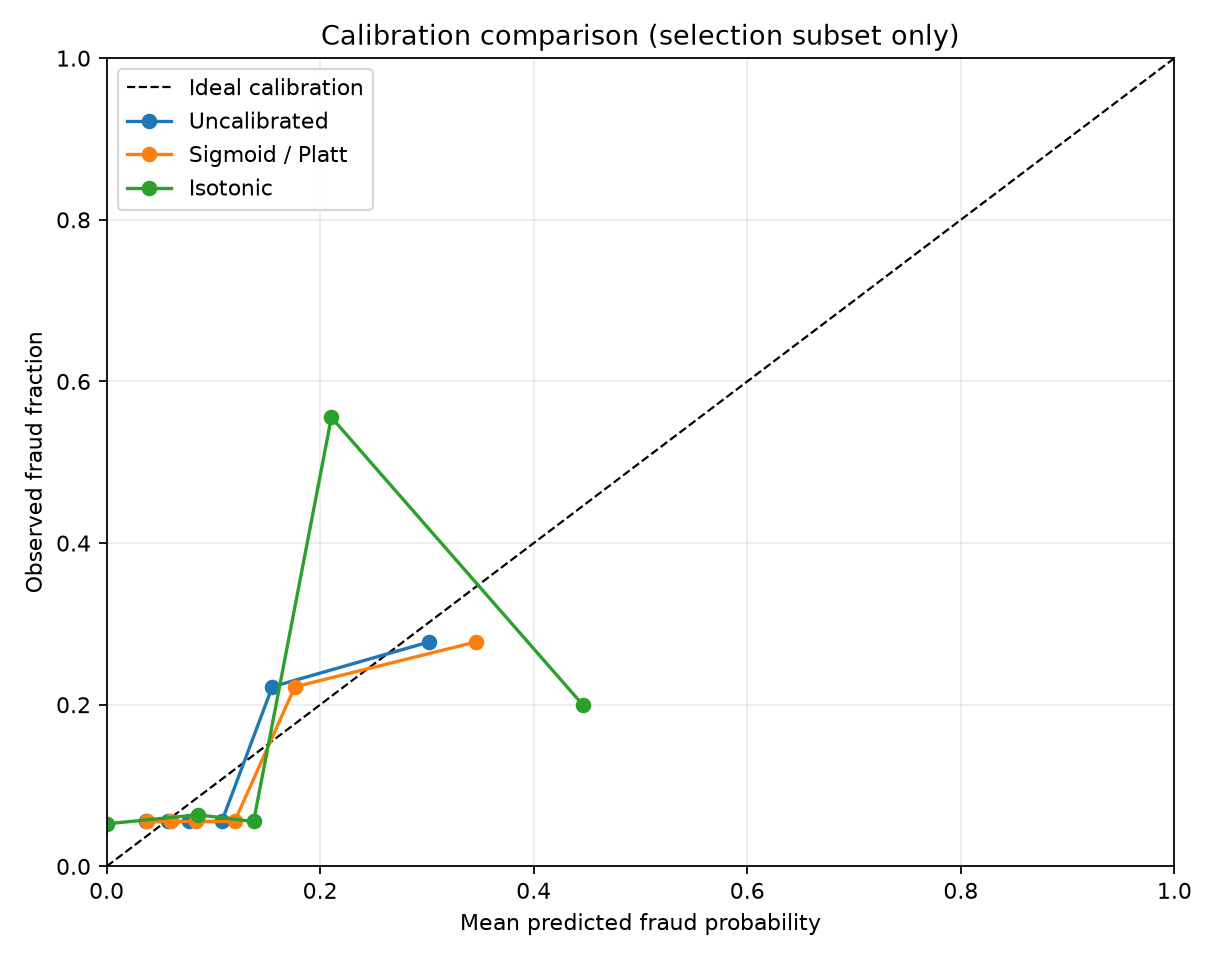

{'input_pipeline': 'models/03_fraud_model_pipeline.joblib',
 'output_calibrated_model': 'models/04_calibrated_model.joblib',
 'fitted_on_partition': 'calibration',
 'calibration_rows': 360,
 'calibration_fit_rows_for_selection': 252,
 'calibration_validation_rows_for_selection': 108,
 'selected_calibrator': 'sigmoid',
 'selected_calibrator_better_brier_than_raw_on_small_holdout': False,
 'selection_metric': 'Brier score; log loss tie-breaker',
 'seed': 42,
 'selected_features': ['hour',
  'day_of_week',
  'transaction_amount',
  'distance_from_usual_location_km',
  'transactions_last_1h',
  'transactions_last_24h',
  'account_age_days',
  'failed_logins_24h',
  'prior_chargebacks',
  'device_age_days',
  'merchant_risk_score',
  'ip_risk_score',
  'email_age_days',
  'login_to_transaction_minutes',
  'card_presence',
  'channel',
  'country',
  'device_type',
  'merchant_category',
  'authentication_level',
  'new_device',
  'billing_address_mismatch',
  'customer_tier'],
 'policy_set_

In [10]:
path=ROOT/'reports/calibration_comparison.csv'
if path.exists(): display(pd.read_csv(path))
plot=ROOT/'reports/calibration_reliability.png'
if plot.exists(): display(Image(filename=str(plot),width=760))
info=ROOT/'models/calibration_metadata.json'
if info.exists(): display(json.loads(info.read_text(encoding='utf-8')))

## E & I. Business cost, decision policy, and operations simulation

Only the **policy partition** was used to select frozen Approve / Manual Review / Block cutoffs. Costs are hypothetical cost units (CU). Review-capacity and false-block safeguards make the operational optimization more realistic. The policy is evaluated against simpler alternatives, including approve-all and the default 0.50 rule.

{'version': '0.1-policy-experiment',
 'model': 'models/04_calibrated_model.joblib',
 'selected_calibration_method': 'sigmoid',
 'model_features': ['hour',
  'day_of_week',
  'transaction_amount',
  'distance_from_usual_location_km',
  'transactions_last_1h',
  'transactions_last_24h',
  'account_age_days',
  'failed_logins_24h',
  'prior_chargebacks',
  'device_age_days',
  'merchant_risk_score',
  'ip_risk_score',
  'email_age_days',
  'login_to_transaction_minutes',
  'card_presence',
  'channel',
  'country',
  'device_type',
  'merchant_category',
  'authentication_level',
  'new_device',
  'billing_address_mismatch',
  'customer_tier'],
 'review_threshold': 0.17180172331090549,
 'block_threshold': 0.4404225000024769,
 'decision_rules': 'Approve if p < review_threshold; Review if review_threshold <= p < block_threshold; Block if p >= block_threshold',
 'selected_on_partition': 'policy',
 'policy_partition_rows': 360,
 'final_test_used': False,
 'cost_currency': 'CU (illustrative; o

reports/05_policy_sensitivity.csv


,scenario,scenario_optimal_review_at,scenario_optimal_block_at,scenario_optimal_cost_cu,scenario_optimal_review_count,scenario_optimal_block_count,base_policy_fixed_review_at,base_policy_fixed_block_at,base_policy_cost_cu_in_scenario,extra_cost_from_unadjusted_policy_cu
0,base,0.171802,0.440423,6045.0740,86,8,0.171802,0.440423,6045.0740,0.0000
1,high_fraud_loss,0.171802,0.440423,10725.7550,86,8,0.171802,0.440423,10725.7550,0.0000
2,high_review_cost,0.171802,0.440423,7211.0740,86,8,0.171802,0.440423,7211.0740,0.0000
3,high_false_block_cost,0.190521,0.500000,6437.6810,77,2,0.171802,0.440423,6503.1635,65.4825
4,less_effective_review,0.171802,0.440423,6896.9330,86,8,0.171802,0.440423,6896.9330,0.0000
5,lower_fraud_loss,0.171802,0.440423,3962.7335,86,8,0.171802,0.440423,3962.7335,0.0000


reports/05_policy_predictions.csv


,transaction_id,fraud_label_policy_only,calibrated_probability,decision,transaction_amount_filled_for_cost,cost_amount_was_missing,hypothetical_realized_cost_cu
0,TXN5000006,1,0.195696,Manual Review,20.03,0,18.006
1,TXN5000021,0,0.070070,Approve,200.53,0,0.000
2,TXN5000022,0,0.091549,Approve,132.03,0,0.000
3,TXN5000023,1,0.224368,Manual Review,49.90,0,23.980
4,TXN5000025,0,0.137055,Approve,88.47,0,0.000
5,TXN5000029,0,0.096526,Approve,114.47,0,0.000
6,TXN5000030,0,0.099293,Approve,264.74,0,0.000
7,TXN5000034,0,0.036800,Approve,28.97,0,0.000
8,TXN5000045,0,0.022849,Approve,22.48,0,0.000
9,TXN5000046,0,0.115247,Approve,169.36,0,0.000


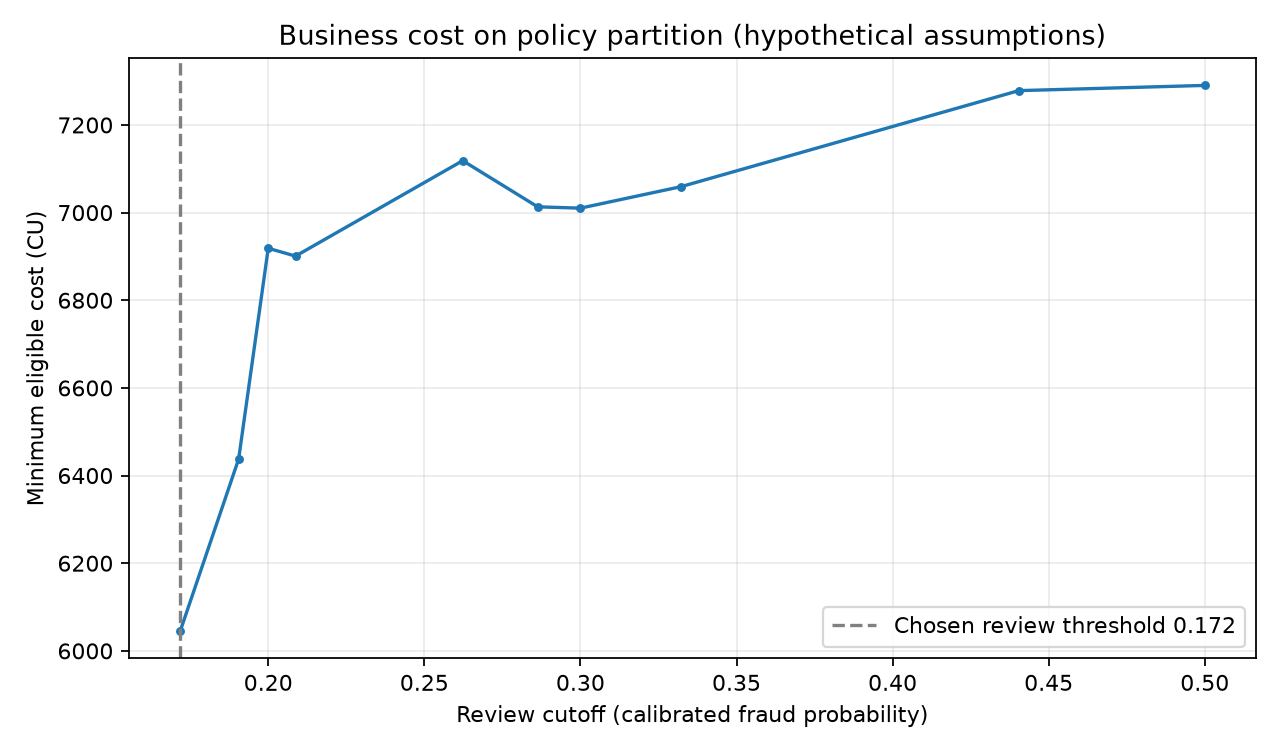

In [11]:
policy_path=ROOT/'models/fraud_decision_policy.json'
if policy_path.exists():
    saved_policy=json.loads(policy_path.read_text(encoding='utf-8'))
    display(saved_policy)
for path in ['reports/05_policy_sensitivity.csv','reports/05_policy_predictions.csv']:
    p=ROOT/path
    if p.exists():
        print(path);display(pd.read_csv(p).head(15))
plot=ROOT/'reports/05_cost_threshold_curve.png'
if plot.exists(): display(Image(filename=str(plot),width=760))

## H. Explainable AI

For the selected Logistic Regression pipeline, permutation importance and exact per-feature **uncalibrated log-odds** contributions are used as a comparable explainability approach; they are **not** SHAP values and **not** causal explanations. Five high-risk transactions and two dependence analyses are provided. The operational probability comes from the separately calibrated model.

01_global_feature_importance.csv


,feature,permutation_pr_auc_decrease_mean,permutation_pr_auc_decrease_std,mean_absolute_log_odds_contribution,mean_signed_log_odds_contribution
0,new_device,0.064730,0.008303,0.227621,0.014254
1,merchant_risk_score,0.052730,0.003953,0.241845,-0.019106
2,merchant_category,0.027492,0.011637,0.151118,0.008619
3,prior_chargebacks,0.021433,0.010338,0.116155,0.004208
4,failed_logins_24h,0.019149,0.007010,0.118949,-0.010240
5,distance_from_usual_location_km,0.019054,0.010727,0.042438,0.014052
6,billing_address_mismatch,0.015871,0.030773,0.176940,0.013523
7,login_to_transaction_minutes,0.013403,0.000885,0.048014,0.006514
8,channel,0.013237,0.005079,0.208203,-0.010337
9,ip_risk_score,0.012873,0.006703,0.129014,-0.000314


04_five_transaction_explanations_summary.csv


,case,transaction_id,actual_fraud_label_POLICY_only,base_model_probability,calibrated_fraud_probability,decision,reference_logit,top_risk_increasing_features,top_risk_decreasing_features
0,1,TXN5002175,1,0.543307,0.584513,Block,-2.208337,transactions_last_1h (+0.759); new_device (+0....,card_presence (-0.090); billing_address_mismat...
1,2,TXN5001513,1,0.461853,0.500501,Block,-2.208337,new_device (+0.650); prior_chargebacks (+0.480...,card_presence (-0.090); billing_address_mismat...
2,3,TXN5000206,0,0.450150,0.488247,Block,-2.208337,billing_address_mismatch (+0.816); merchant_ri...,failed_logins_24h (-0.086); day_of_week (-0.09...
3,4,TXN5002809,1,0.397356,0.432438,Manual Review,-2.208337,billing_address_mismatch (+0.816); new_device ...,country (-0.149); channel (-0.220); account_ag...
4,5,TXN5000060,1,0.395752,0.430729,Manual Review,-2.208337,new_device (+0.650); prior_chargebacks (+0.480...,billing_address_mismatch (-0.092); channel (-0...


07_dependence_summary.csv


,feature_x,feature_y,min_mean_probability,max_mean_probability,range_probability_points,figure,warning
0,new_device,distance_from_usual_location_km,0.100216,0.204848,0.104631,05_new_device_x_distance_dependence.png,Not a causal interaction or explicit learned l...
1,merchant_risk_score,transaction_amount,0.082749,0.171557,0.088808,06_amount_x_merchant_risk_dependence.png,Not a causal interaction or explicit learned l...


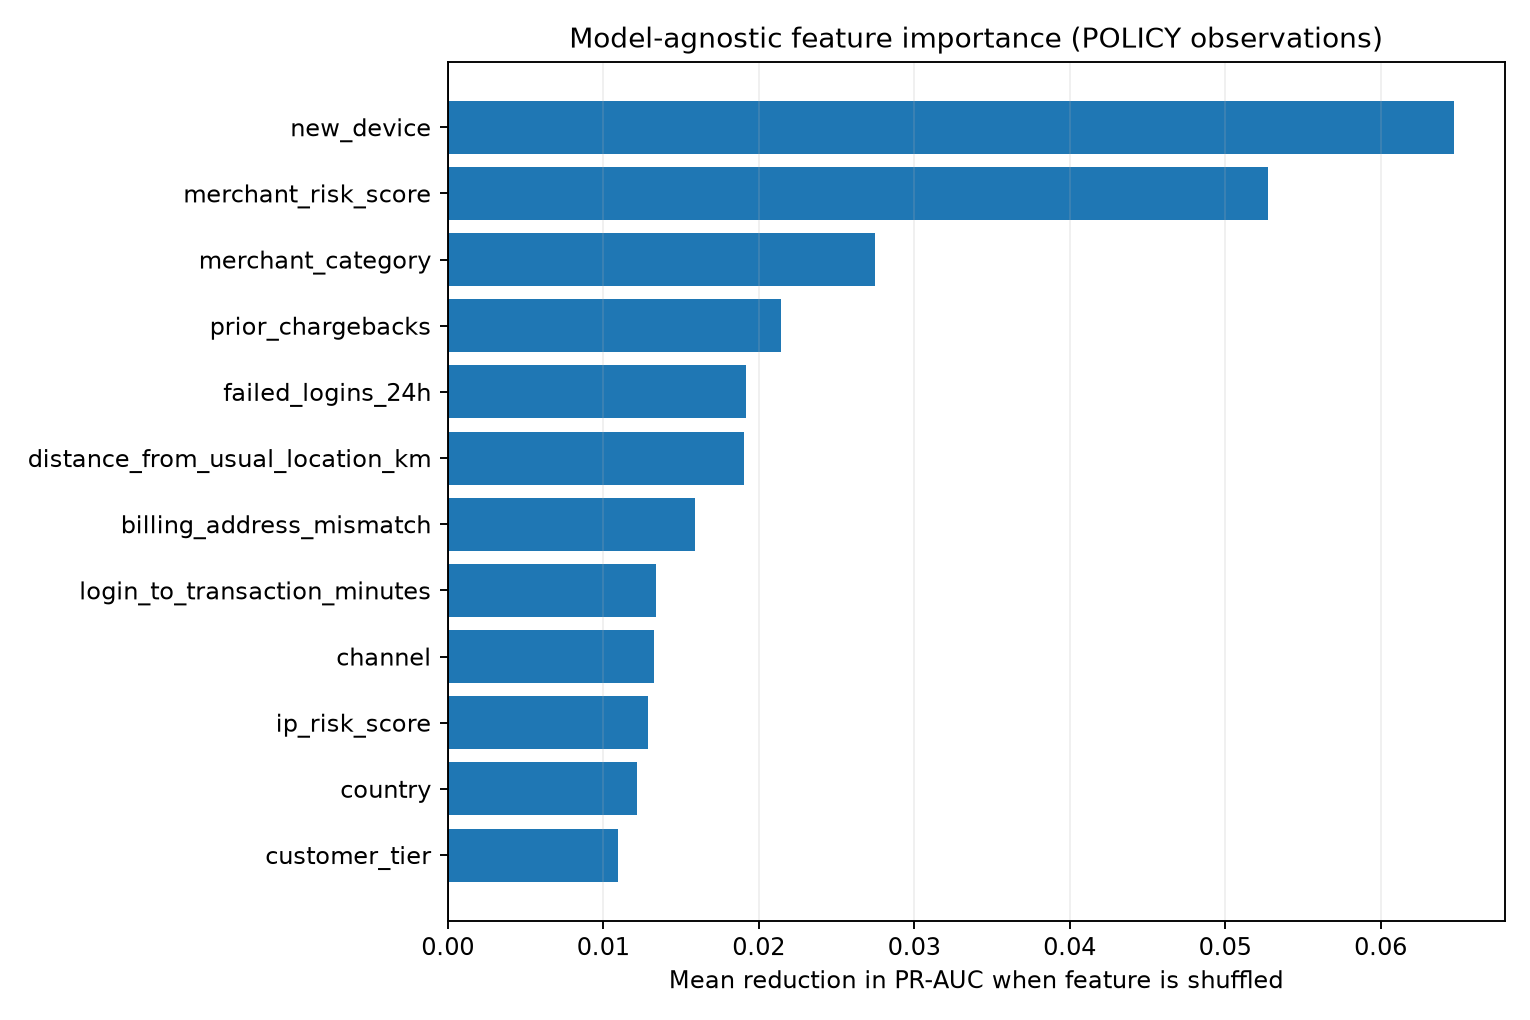

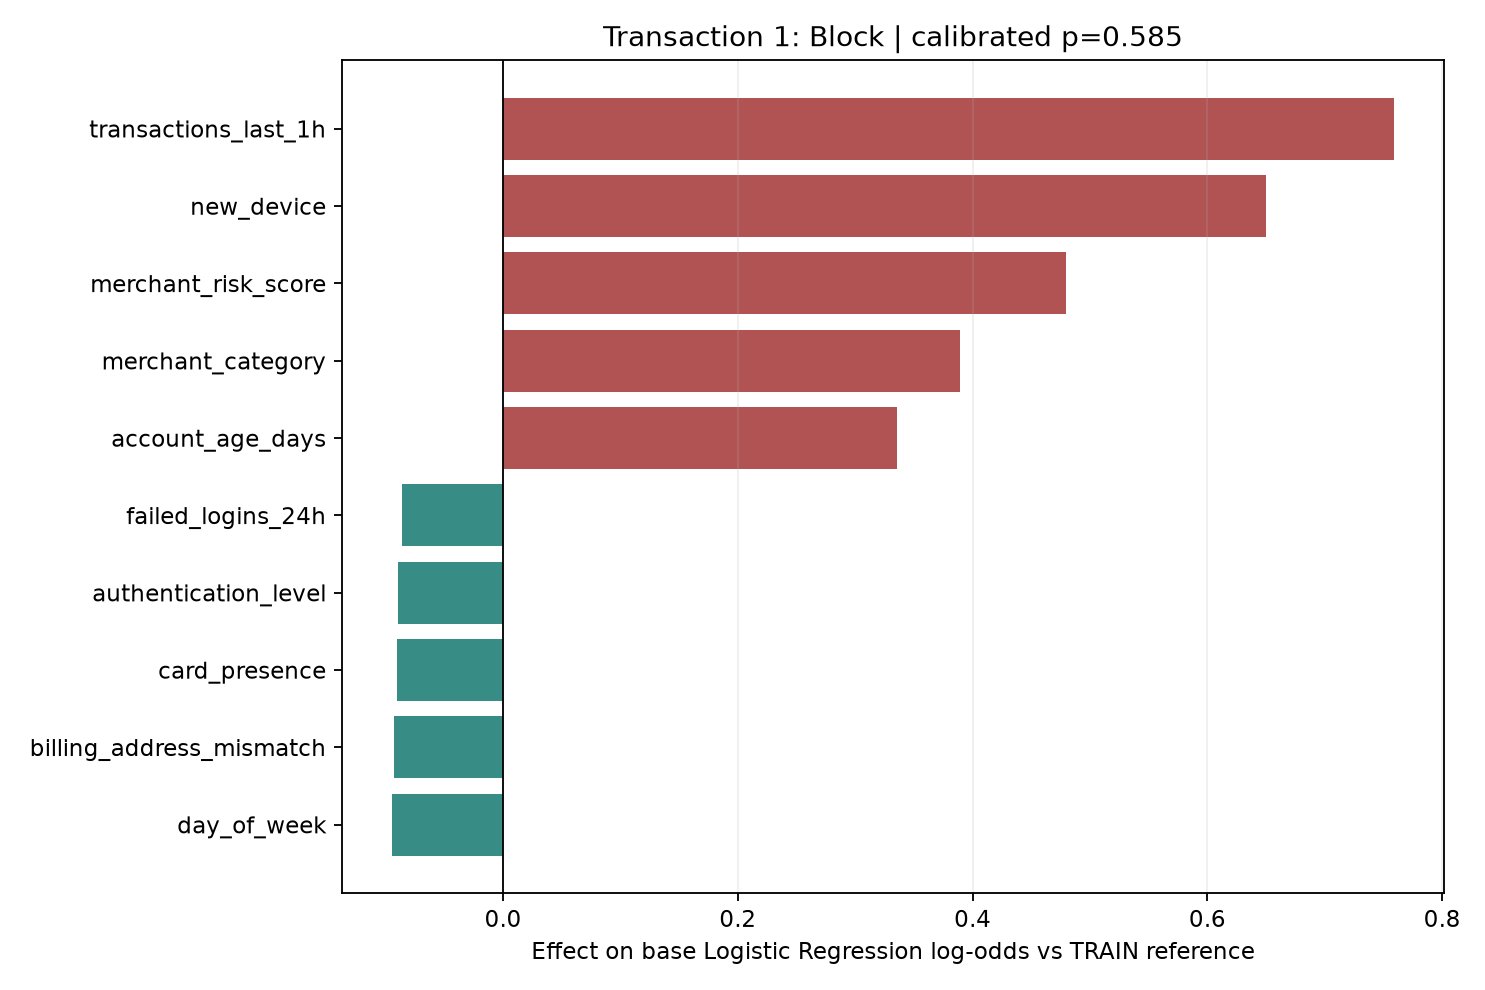

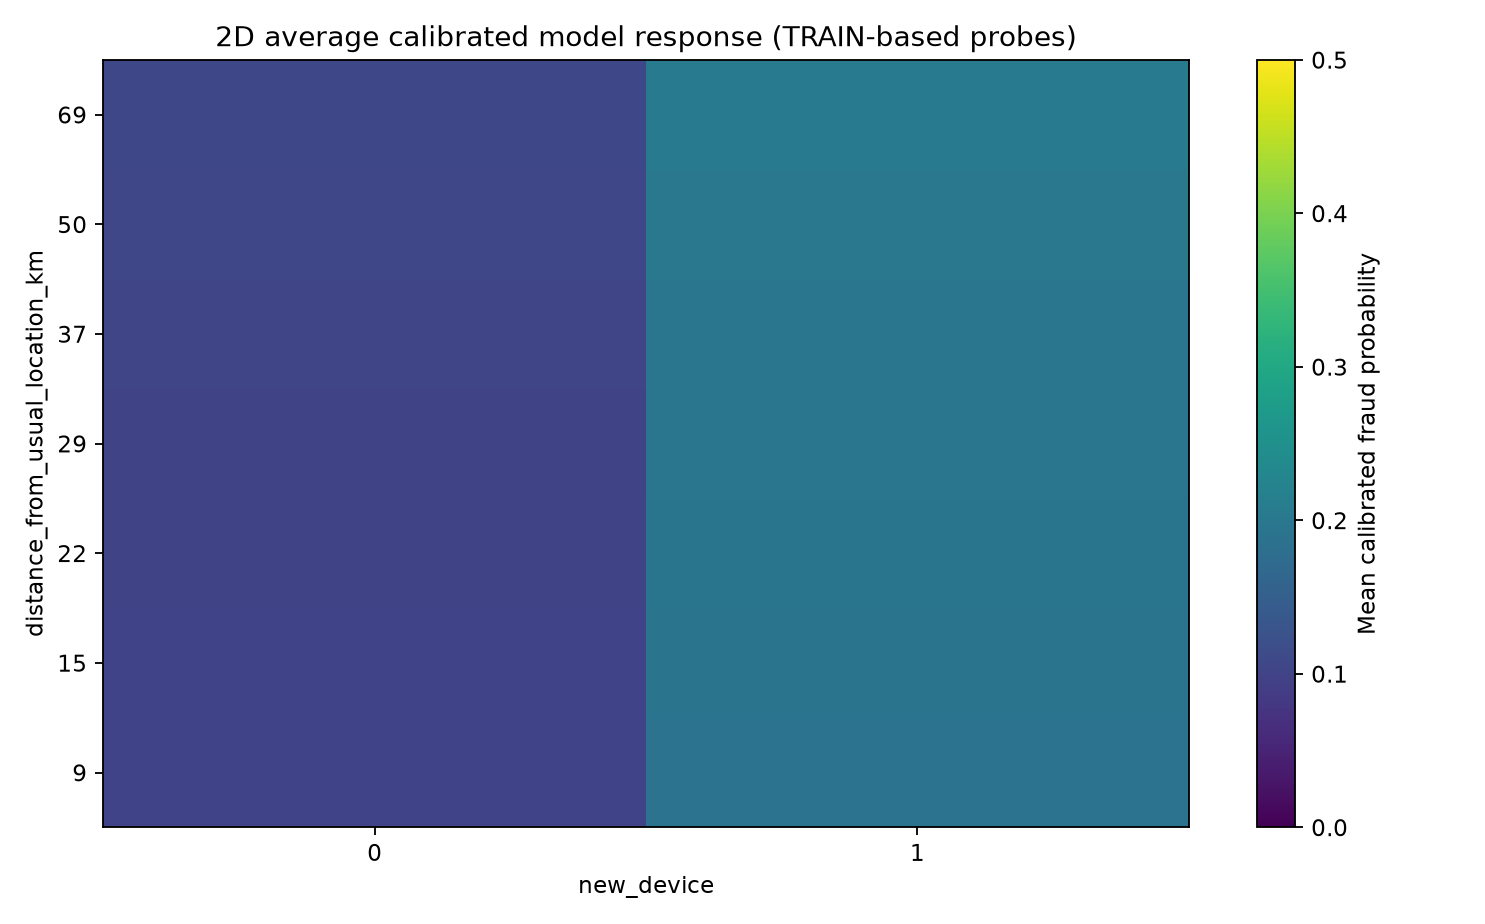

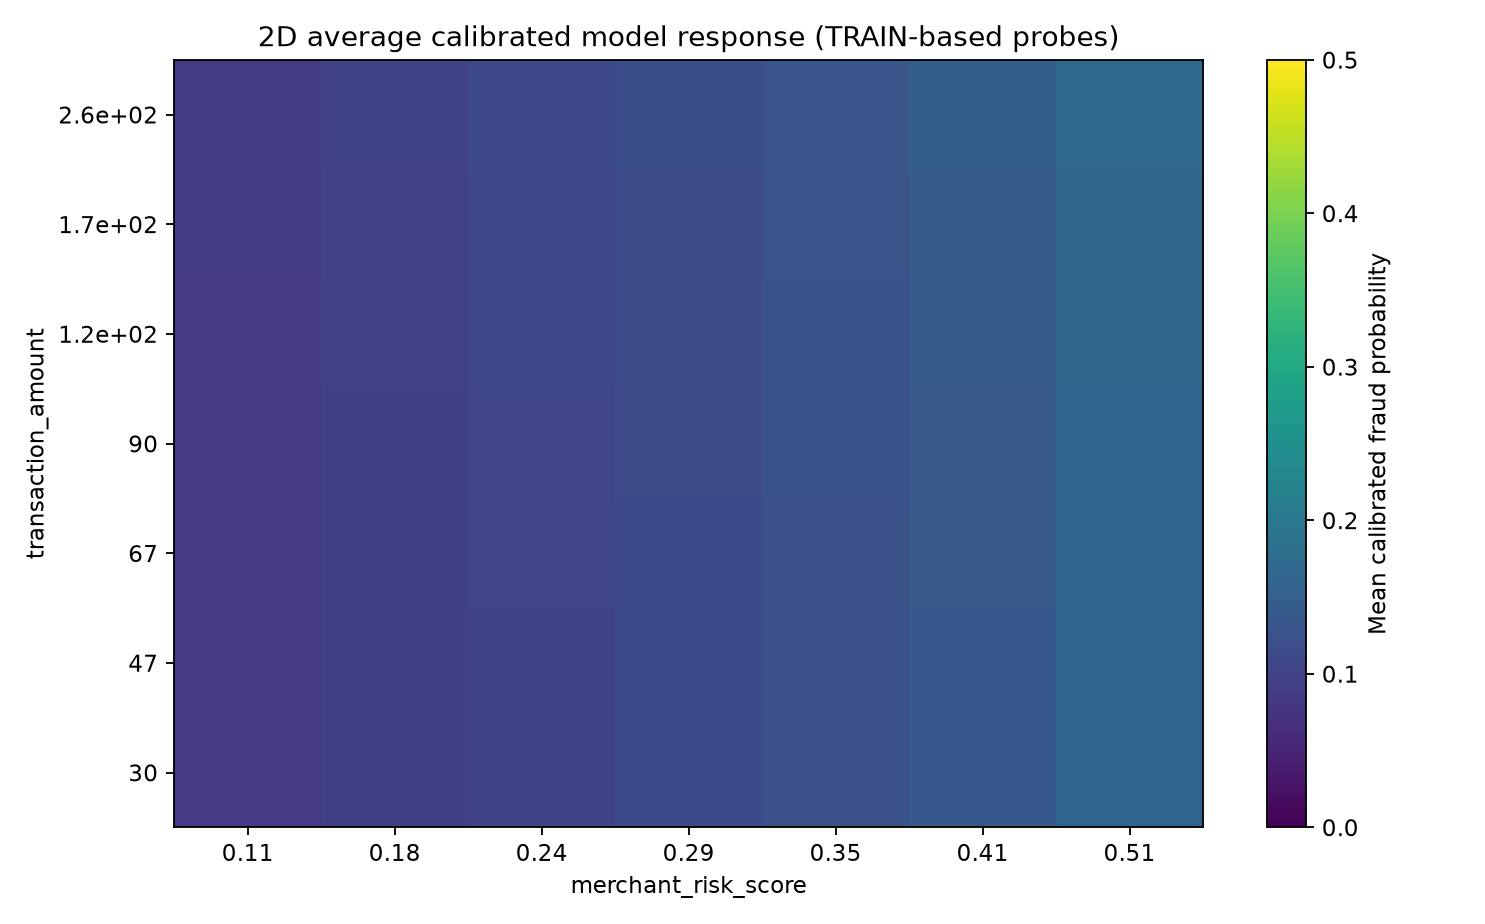

In [12]:
expl=ROOT/'reports/explainability'
for filename in ['01_global_feature_importance.csv','04_five_transaction_explanations_summary.csv','07_dependence_summary.csv']:
    p=expl/filename
    if p.exists():
        print(filename);display(pd.read_csv(p).head(15))
for filename in ['02_global_feature_importance.png','transaction_1_explanation.png','05_new_device_x_distance_dependence.png','06_amount_x_merchant_risk_dependence.png']:
    p=expl/filename
    if p.exists():display(Image(filename=str(p),width=760))

## J. Robustness and stress testing

CV-fold variability and artificial shifts in transaction amount, velocity, missingness, and channel mix measure model sensitivity. They do **not** prove future performance under real fraud changes. Particular attention is needed when predicted manual-review volume exceeds capacity.

01_cv_fold_results.csv


,fold,train_rows,validation_rows,validation_frauds,pr_auc,roc_auc,precision_at_0_50,recall_at_0_50,f1_at_0_50
0,1,1120,560,68,0.259615,0.697543,0.333333,0.014706,0.028169
1,2,1120,560,68,0.245522,0.669566,0.250000,0.014706,0.027778
2,3,1120,560,68,0.213240,0.678802,0.333333,0.014706,0.028169


03_feature_stability.csv


,feature,mean_pr_auc_decrease,std_pr_auc_decrease,top_5_fold_count
0,billing_address_mismatch,0.031735,0.013069,3
1,merchant_risk_score,0.026296,0.000984,3
2,new_device,0.019563,0.012537,2
3,prior_chargebacks,0.016982,0.007463,2
4,transactions_last_1h,0.016397,0.012946,2
5,authentication_level,0.010420,0.003364,2
6,merchant_category,0.012688,0.004363,1
7,channel,0.013681,0.005746,0
8,account_age_days,0.010290,0.003650,0
9,transaction_amount,0.003530,0.001074,0


04_scenario_comparison.csv


,scenario,simulated_change,rows_modified,n_policy_records,mean_fraud_probability,p95_fraud_probability,mean_absolute_score_change,p95_absolute_score_change,decision_change_count,approve_count,review_count,block_count,review_share,block_share
0,baseline,unchanged policy validation rows,0,360,0.134587,0.351516,0.000000,0.000000,0,266,86,8,0.238889,0.022222
1,amount_50pct_increase,all known transaction amounts multiplied by 1.5,355,360,0.137239,0.369187,0.002652,0.008990,4,262,90,8,0.250000,0.022222
2,extreme_amount_5pct,set 5% of policy amounts to 3x TRAIN 99th perc...,18,360,0.139542,0.365123,0.004955,0.001288,7,261,89,10,0.247222,0.027778
3,amount_missing_20pct,add missing amount values for approx. 20% of p...,72,360,0.134249,0.351246,0.000583,0.003217,1,267,85,8,0.236111,0.022222
4,velocity_surge,add 3 recent 1h transactions and 5 recent 24h ...,360,360,0.214101,0.504285,0.079514,0.152328,104,185,144,31,0.400000,0.086111
5,merchant_risk_missing_20pct,remove merchant-risk scores in approx. 20% of ...,72,360,0.132265,0.353156,0.005771,0.040019,9,273,79,8,0.219444,0.022222
6,channel_mix_shift,switch up to 30% of rows to TRAIN-common chann...,108,360,0.148892,0.369150,0.014305,0.074997,21,248,101,11,0.280556,0.030556


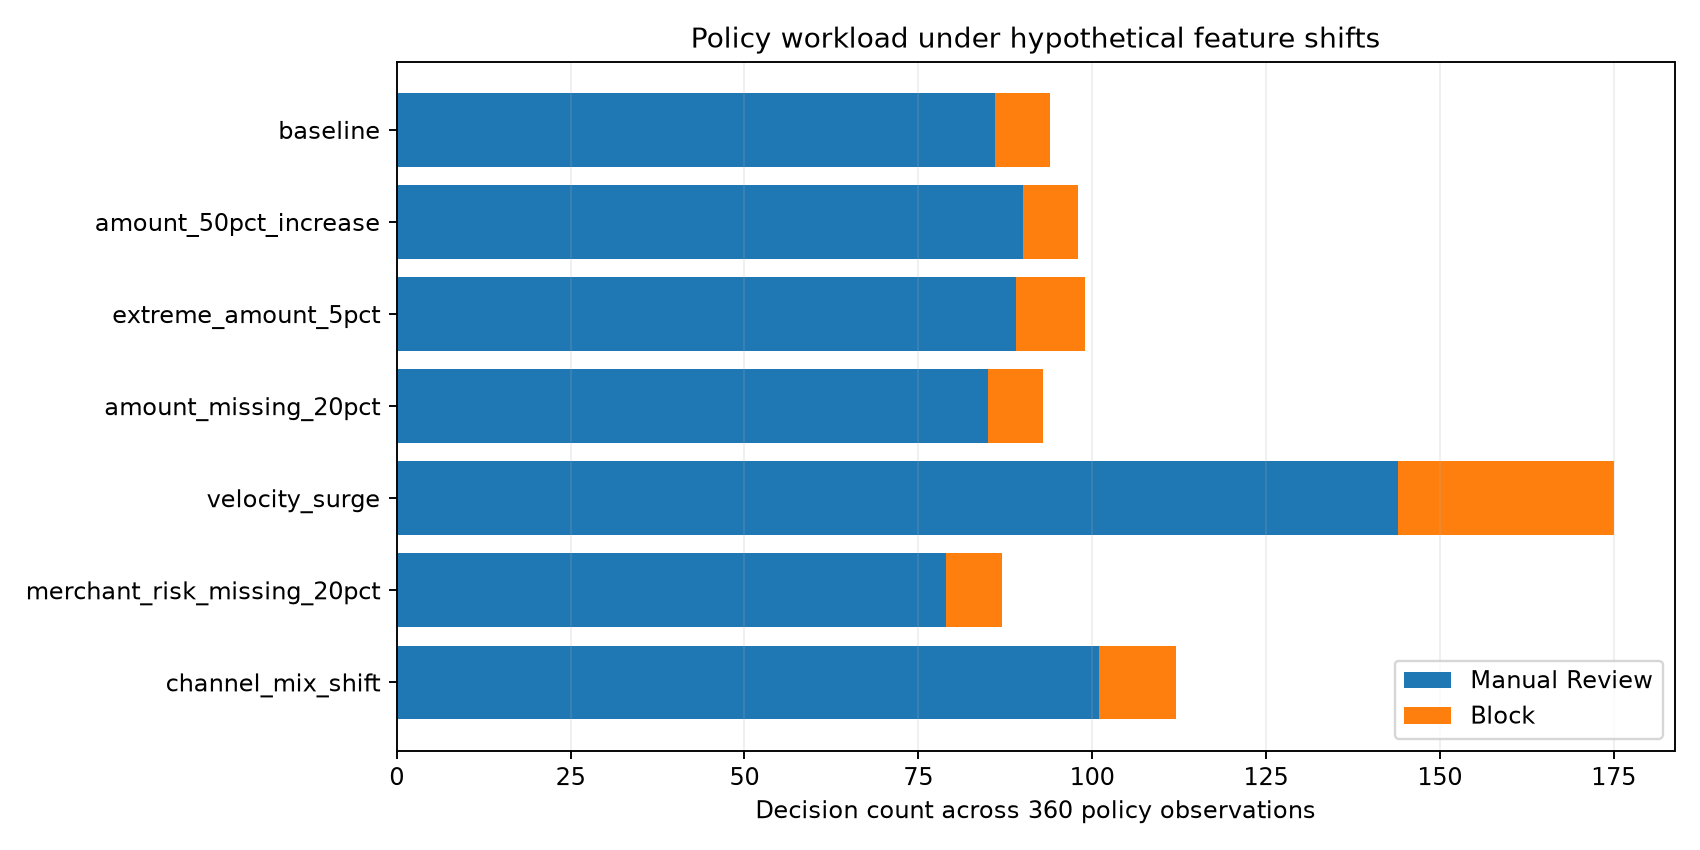

In [13]:
rob=ROOT/'reports/robustness'
for filename in ['01_cv_fold_results.csv','03_feature_stability.csv','04_scenario_comparison.csv']:
    p=rob/filename
    if p.exists():
        print(filename);display(pd.read_csv(p).head(25))
plot=rob/'05_stress_decision_chart.png'
if plot.exists():display(Image(filename=str(plot),width=760))

## Final held-out test: frozen model and policy

**Do not use final test results to retune a model, calibrator, or threshold.** The single saved evaluation summarizes performance for the fixed policy. All code below reads existing CSV/JSON/PNG reports; it does not run inference again.

{'evaluation_scope': 'one-time final test; no fitting/tuning/threshold optimization',
 'test_rows': 600,
 'fraud_rows': 73,
 'model_family': 'Logistic Regression',
 'feature_mode': 'raw',
 'calibration_method': 'sigmoid',
 'selected_thresholds_from_policy_only': {'review': 0.17180172331090549,
  'block': 0.4404225000024769},
 'ranking_and_calibration': {'roc_auc': 0.6647604689246446,
  'pr_auc_average_precision': 0.21914800471901494,
  'brier_score': 0.10438733861076187,
  'log_loss': 0.3554727760596556,
  'fraud_prevalence': 0.12166666666666667},
 'binary_at_0_50': {'threshold': 0.5,
  'accuracy': 0.8716666666666667,
  'precision': 0.25,
  'recall': 0.0273972602739726,
  'f1': 0.04938271604938271,
  'tp': 2,
  'fp': 6,
  'tn': 521,
  'fn': 71,
  'predicted_fraud': 8},
 'flag_at_frozen_review_cutoff': {'threshold': 0.17180172331090549,
  'accuracy': 0.7583333333333333,
  'precision': 0.21875,
  'recall': 0.3835616438356164,
  'f1': 0.27860696517412936,
  'tp': 28,
  'fp': 100,
  'tn': 

02_classification_metrics.csv


,metric_rule,threshold,accuracy,precision,recall,f1,tp,fp,tn,fn,predicted_fraud
0,binary >= 0.50,0.500000,0.871667,0.25000,0.027397,0.049383,2,6,521,71,8
1,flag at frozen review cutoff,0.171802,0.758333,0.21875,0.383562,0.278607,28,100,427,45,128


03_policy_comparison.csv


,policy,n_transactions,approved,reviewed,blocked,review_share,legitimate_reviewed,legitimate_blocked,legit_block_rate,fraud_approved,fraud_reviewed,fraud_blocked,fraud_flagged,flagged_fraud_recall,flagged_precision,expected_review_fraud_stops,expected_total_fraud_stops,total_cost_cu
0,Frozen 3-way policy,600,472,117,11,0.195000,92,8,0.015180,45,25,3,28,0.383562,0.21875,20.0,23.0,10668.365
1,Approve all,600,600,0,0,0.000000,0,0,0.000000,73,0,0,0,0.000000,0.00000,0.0,0.0,15073.350
2,Binary 0.50 (block positive),600,592,0,8,0.000000,0,6,0.011385,71,0,2,2,0.027397,0.25000,0.0,2.0,14822.639
3,Review at 0.50 (never block),600,592,8,0,0.013333,6,0,0.000000,71,2,0,2,0.027397,0.25000,1.6,1.6,14811.646


04_frozen_policy_sensitivity.csv


,scenario,n_transactions,approved,reviewed,blocked,review_share,legitimate_reviewed,legitimate_blocked,legit_block_rate,fraud_approved,fraud_reviewed,fraud_blocked,fraud_flagged,flagged_fraud_recall,flagged_precision,expected_review_fraud_stops,expected_total_fraud_stops,total_cost_cu
0,base,600,472,117,11,0.195,92,8,0.01518,45,25,3,28,0.383562,0.21875,20.0,23.0,10668.3650
1,high_fraud_loss,600,472,117,11,0.195,92,8,0.01518,45,25,3,28,0.383562,0.21875,20.0,23.0,19396.4290
2,high_review_cost,600,472,117,11,0.195,92,8,0.01518,45,25,3,28,0.383562,0.21875,20.0,23.0,12256.3650
3,high_false_block_cost,600,472,117,11,0.195,92,8,0.01518,45,25,3,28,0.383562,0.21875,20.0,23.0,11186.3165
4,less_effective_review,600,472,117,11,0.195,92,8,0.01518,45,25,3,28,0.383562,0.21875,12.5,15.5,12392.2685
5,lower_fraud_loss,600,472,117,11,0.195,92,8,0.01518,45,25,3,28,0.383562,0.21875,20.0,23.0,6804.3330


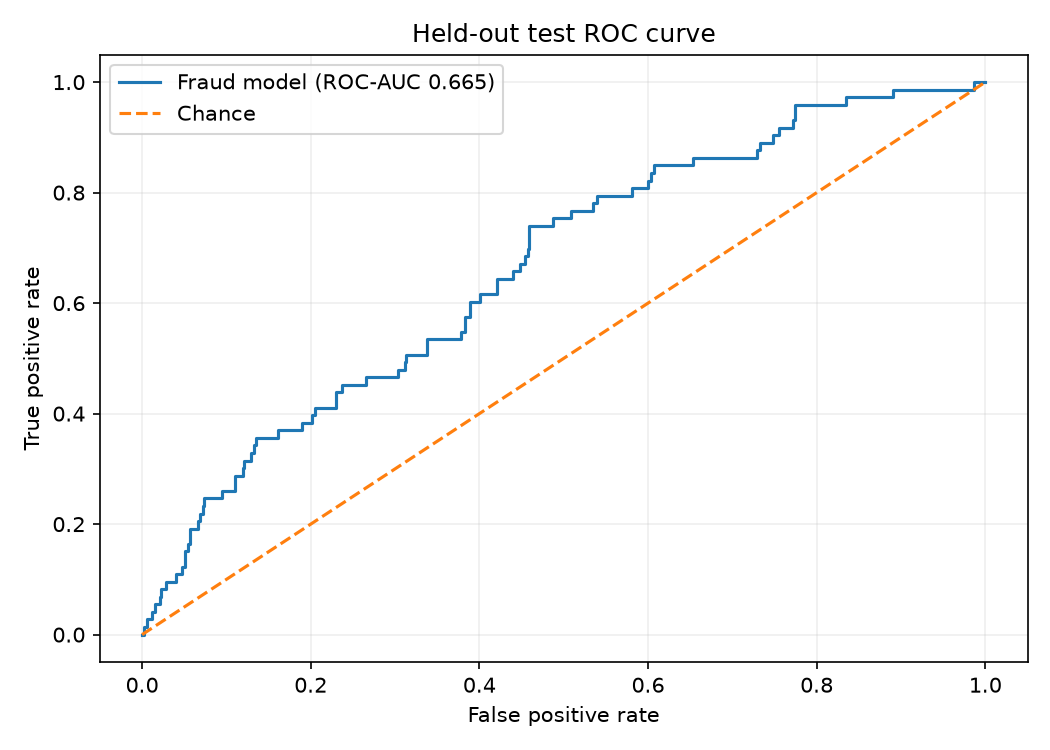

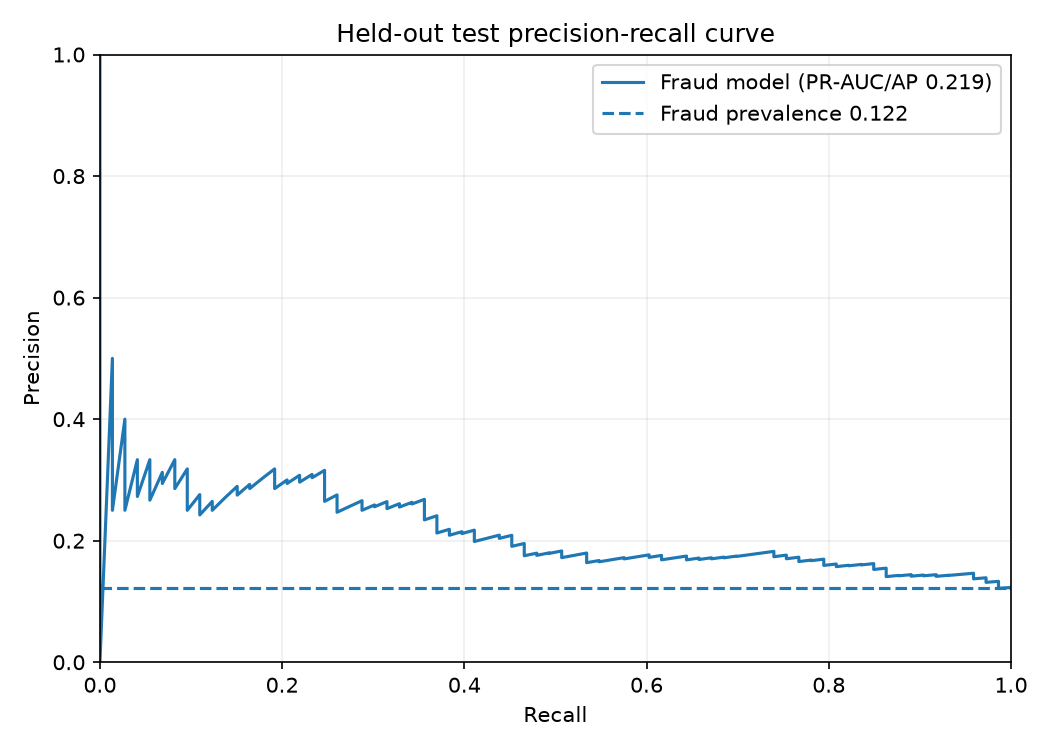

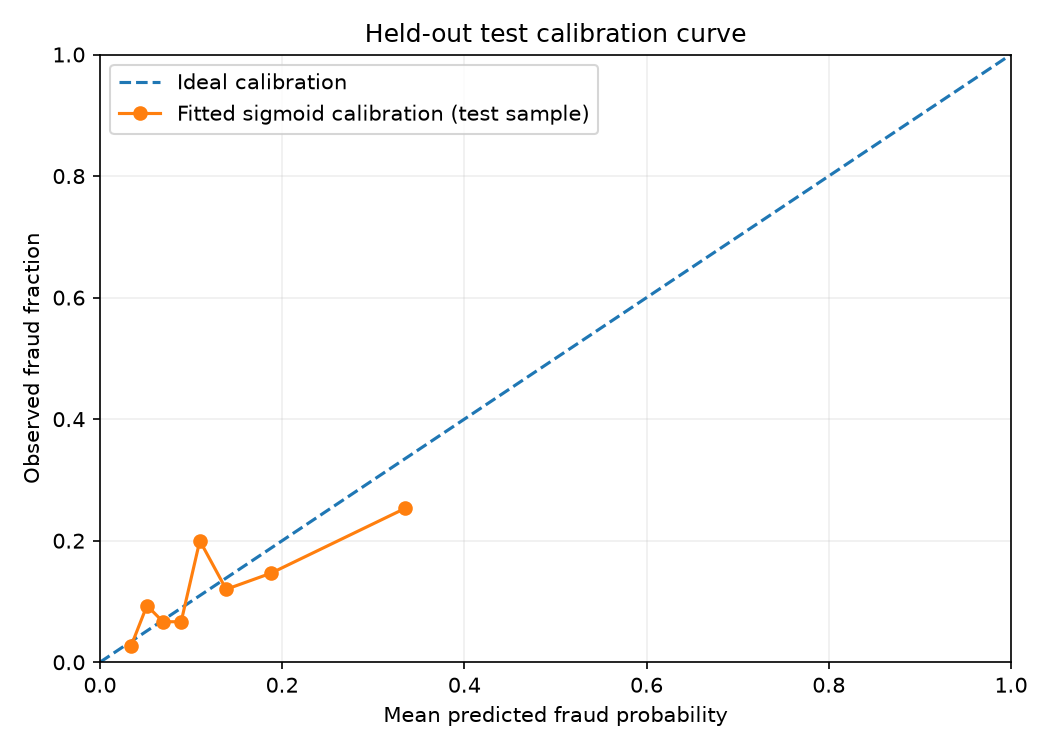

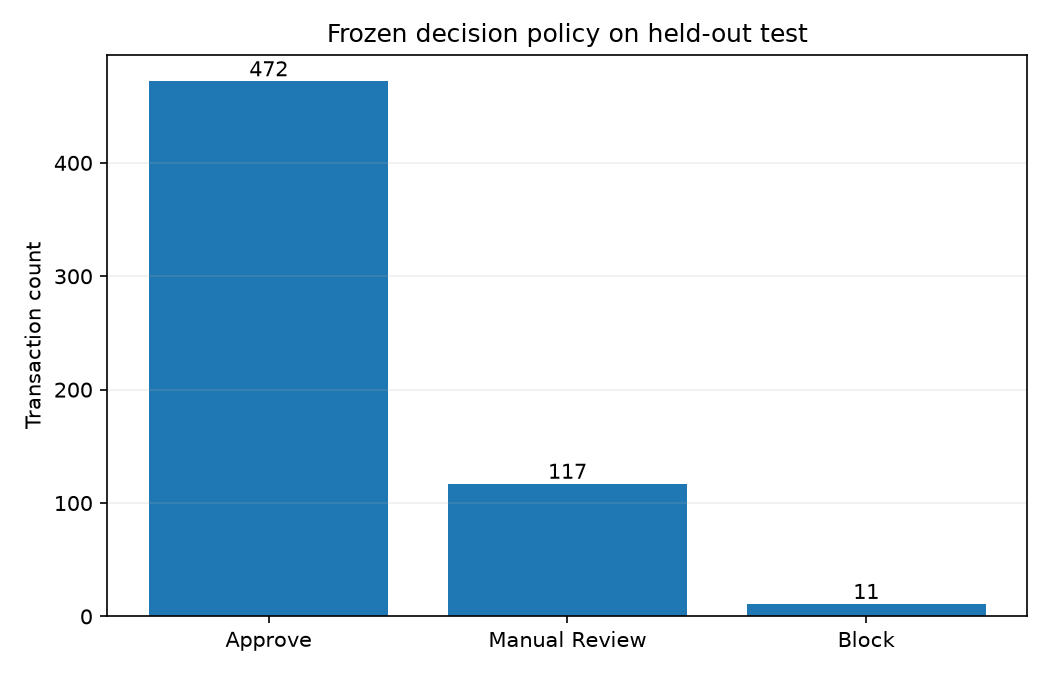

In [14]:
final=ROOT/'reports/final_evaluation'
metric_path=final/'10_final_test_metrics.json'
if metric_path.exists():
    display(json.loads(metric_path.read_text(encoding='utf-8')))
else:
    print('Missing final metrics:',metric_path)
for name in ['02_classification_metrics.csv','03_policy_comparison.csv','04_frozen_policy_sensitivity.csv']:
    p=final/name
    if p.exists():
        print(name);display(pd.read_csv(p).head(30))
for name in ['06_roc_curve.png','07_precision_recall_curve.png','08_calibration_curve.png','09_decision_counts.png']:
    p=final/name
    if p.exists():display(Image(filename=str(p),width=760))

## K. Model governance and business recommendations

The model card documents assumptions, intended use, evaluation, model risks, and monitoring. The 10-page business report presents measured outcomes and explicit hypothetical cost assumptions. Suggested monitoring: missingness/feature freshness, drift, risk score distributions, review/block volumes, capture/false blocks after delayed labels arrive, and realized costs. **No production deployment is approved.**

In [15]:
for filename in ['06_model_card.pdf','07_business_fraud_strategy.pdf']:
    p=ROOT/filename
    print(('FOUND' if p.exists() else 'MISSING'),filename)
print('For full documentation, open:',ROOT/'08_README.md')

FOUND 06_model_card.pdf
FOUND 07_business_fraud_strategy.pdf
For full documentation, open: c:\Users\ASUS\Desktop\Internship\fraud-risk-intelligence-day01\08_README.md


## Required deliverables checklist

These are the **eight filenames required by the internship assessment**. They are located across the existing project folders. For submission, copy these eight into a separate `submission/` folder; retain `src/`, dataset source and supplementary reports in your development folder for reproducibility.

In [16]:
deliverables = {
    '01_fraud_risk_analysis.ipynb':'01_fraud_risk_analysis.ipynb',
    '02_processed_dataset.csv':'data/processed/02_processed_dataset.csv',
    '03_fraud_model_pipeline.joblib':'models/03_fraud_model_pipeline.joblib',
    '04_calibrated_model.joblib':'models/04_calibrated_model.joblib',
    '05_threshold_cost_analysis.csv':'reports/05_threshold_cost_analysis.csv',
    '06_model_card.pdf':'06_model_card.pdf',
    '07_business_fraud_strategy.pdf':'07_business_fraud_strategy.pdf',
    '08_README.md':'08_README.md',
}
check=pd.DataFrame([{'required_file':k,'location':v,'found':(ROOT/v).is_file()} for k,v in deliverables.items()])
display(check)
print(f"{int(check.found.sum())} / {len(check)} required artifacts found")
if not check.found.all():print('Add missing files before submitting; do not retrain just to make this checklist pass.')

,required_file,location,found
0,01_fraud_risk_analysis.ipynb,01_fraud_risk_analysis.ipynb,True
1,02_processed_dataset.csv,data/processed/02_processed_dataset.csv,True
2,03_fraud_model_pipeline.joblib,models/03_fraud_model_pipeline.joblib,True
3,04_calibrated_model.joblib,models/04_calibrated_model.joblib,True
4,05_threshold_cost_analysis.csv,reports/05_threshold_cost_analysis.csv,True
5,06_model_card.pdf,06_model_card.pdf,True
6,07_business_fraud_strategy.pdf,07_business_fraud_strategy.pdf,True
7,08_README.md,08_README.md,True


8 / 8 required artifacts found


In [17]:
print(check.loc[~check["found"], ["required_file", "location"]].to_string(index=False))

Empty DataFrame
Columns: [required_file, location]
Index: []


### Key limitations to state in the final assessment

1. No real transaction timestamp or customer ID, so prospective time-based and customer-group leakage controls cannot be fully tested.
2. Calibration did not necessarily outperform raw scores on the selection subset.
3. Hypothetical financial costs, review effectiveness and capacity assumptions are not observed operational costs.
4. The held-out test revealed material missed fraud and imperfect ranking; do not claim production readiness.
5. Dependence/permutation importance and model contributions are associative/predictive descriptions, **not** proof of causal relationships.

To reproduce the entire analysis independently, use the **fresh-copy** execution procedure in `08_README.md` with a new fixed-seed run. Do not modify the finalized saved experiment based on the final test results.